# 04 · Sensibilidad y evaluación

**Etapa 5.** Objetivo: comprobar si las conclusiones del notebook 03 dependen de decisiones que tomamos (cómo medir el uso de IA, qué controles usar, qué estudiantes incluir, qué área mirar).

No es una búsqueda de resultados significativos: se eligen pocas variantes razonables, decididas de antemano, y se compara cada una con el resultado base. Se mira sobre todo si el **signo y el tamaño** de la asociación se mantienen.

El resultado base es H4: coeficiente de la frecuencia de IA sobre el puntaje de ciencias, ajustado por ESCS, sexo y grado (+4,0 puntos por punto de frecuencia en la escala 1 a 5).

In [1]:
from pathlib import Path
from math import erfc, sqrt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

raiz = Path.cwd()
while not (raiz / "README.md").exists():
    if raiz == raiz.parent:
        raise FileNotFoundError("No se encontró README.md: ejecutá el notebook dentro del proyecto.")
    raiz = raiz.parent

archivo = raiz / "data" / "processed" / "argentina_pisa2025_analitico.csv"
carpeta_figuras = raiz / "reports" / "figures"
carpeta_tablas = raiz / "reports" / "tables"

datos = pd.read_csv(archivo)
print("Estudiantes de Argentina:", len(datos))

Estudiantes de Argentina: 11092


## 1. Funciones de estimación

Son las mismas del notebook 03 (peso final, 80 pesos replicados y 10 valores plausibles con las reglas de Rubin).

In [2]:
N_REPLICAS = 80
FACTOR_FAY = 0.5
DIVISOR = N_REPLICAS * (1 - FACTOR_FAY) ** 2     # 80 * 0.25 = 20

pesos_replicados = []
for i in range(1, 81):
    pesos_replicados.append("W_FSTURWT" + str(i))

pv_ciencias = []
pv_matematica = []
pv_lectura = []
for i in range(1, 11):
    pv_ciencias.append("PV" + str(i) + "SCIE")
    pv_matematica.append("PV" + str(i) + "MATH")
    pv_lectura.append("PV" + str(i) + "READ")

print("Divisor de la fórmula:", DIVISOR)

Divisor de la fórmula: 20.0


In [3]:
def media_pv(datos, pv, peso):
    media = np.average(datos[pv].values, weights=datos[peso].values)
    return np.array([media])


def media_variable(datos, pv, peso, variable):
    # pv no se usa acá: se deja para que todas las funciones reciban los mismos argumentos
    media = np.average(datos[variable].values, weights=datos[peso].values)
    return np.array([media])


def diferencia_pv(datos, pv, peso, columna, grupo_a, grupo_b):
    a = datos[datos[columna] == grupo_a]
    b = datos[datos[columna] == grupo_b]
    media_a = np.average(a[pv].values, weights=a[peso].values)
    media_b = np.average(b[pv].values, weights=b[peso].values)
    return np.array([media_a - media_b])


def diferencia_variable(datos, pv, peso, columna, grupo_a, grupo_b, variable):
    # pv no se usa acá, igual que en media_variable
    a = datos[datos[columna] == grupo_a]
    b = datos[datos[columna] == grupo_b]
    media_a = np.average(a[variable].values, weights=a[peso].values)
    media_b = np.average(b[variable].values, weights=b[peso].values)
    return np.array([media_a - media_b])


def regresion_pv(datos, pv, peso, predictores):
    y = datos[pv].values
    w = datos[peso].values
    columnas = [np.ones(len(datos))]
    for predictor in predictores:
        columnas.append(datos[predictor].values)
    X = np.column_stack(columnas)
    raiz_w = np.sqrt(w)
    coeficientes = np.linalg.lstsq(X * raiz_w[:, None], y * raiz_w, rcond=None)[0]
    return coeficientes

In [4]:
def estimar(datos, funcion, pvs, **argumentos):
    estimaciones = []
    varianzas = []

    for pv in pvs:
        estimacion = funcion(datos, pv, "W_FSTUWT", **argumentos)

        replicas = []
        for peso_replicado in pesos_replicados:
            replicas.append(funcion(datos, pv, peso_replicado, **argumentos))
        replicas = np.array(replicas)

        varianza_muestral = np.sum((replicas - estimacion) ** 2, axis=0) / DIVISOR
        estimaciones.append(estimacion)
        varianzas.append(varianza_muestral)

    estimaciones = np.array(estimaciones)
    varianzas = np.array(varianzas)
    m = len(pvs)

    estimacion_final = estimaciones.mean(axis=0)
    varianza_muestral = varianzas.mean(axis=0)
    if m > 1:
        varianza_entre_pv = estimaciones.var(axis=0, ddof=1)
    else:
        varianza_entre_pv = 0

    varianza_total = varianza_muestral + (1 + 1 / m) * varianza_entre_pv
    return estimacion_final, np.sqrt(varianza_total)

In [5]:
resultados = []

def guardar(hipotesis, parametro, n, estimacion, error, nota=""):
    z = estimacion / error
    p = erfc(abs(z) / sqrt(2))
    if p < 0.0001:
        texto_p = "<0,0001"
    else:
        texto_p = str(round(p, 4))
    inferior = estimacion - 1.96 * error
    superior = estimacion + 1.96 * error
    if p < 0.05 and (inferior > 0 or superior < 0):
        veredicto = "compatible con una asociación"
    else:
        veredicto = "evidencia insuficiente"
    resultados.append({
        "hipotesis": hipotesis, "parametro": parametro, "n": n,
        "estimacion": round(estimacion, 3), "error_estandar": round(error, 3),
        "ic95_inferior": round(inferior, 3), "ic95_superior": round(superior, 3),
        "p": p, "p_texto": texto_p, "veredicto": veredicto, "nota": nota,
    })

## 2. Muestras y variables para las variantes

In [6]:
muestra_escs = datos[datos["ESCS"].notna()].copy()
muestra_ia = muestra_escs[muestra_escs["ia_estado"] == "respondio_las_4"].copy()

ia_4 = ["ST438Q01DA", "ST438Q02DA", "ST438Q03DA", "ST438Q04DA"]

# Variantes de la exposición (solo para quienes contestaron las 4)
muestra_ia["usa_alguna"] = (muestra_ia[ia_4].max(axis=1) > 1).astype(int)
muestra_ia["usa_semanal_alguna"] = (muestra_ia[ia_4].max(axis=1) >= 4).astype(int)

# Variante de la muestra: estudiantes con al menos una pregunta de IA contestada (promedio de las que contestaron)
muestra_disponible = muestra_escs[muestra_escs["ia_cantidad_respondidas"] >= 1].copy()
muestra_disponible["ia_promedio_disp"] = muestra_disponible[ia_4].mean(axis=1)

# Variante: índice de uso de IA en la escuela que calcula PISA
muestra_indice = muestra_escs[muestra_escs["AIUSESCH"].notna()].copy()

print("Muestra base (ESCS y 4 preguntas):", len(muestra_ia))
print("Muestra con al menos 1 pregunta:", len(muestra_disponible))
print("Muestra con índice AIUSESCH:", len(muestra_indice))
print("Usan alguna vez alguna actividad:", muestra_ia["usa_alguna"].sum(), "| usan semanal o más alguna:", muestra_ia["usa_semanal_alguna"].sum())

Muestra base (ESCS y 4 preguntas): 7191
Muestra con al menos 1 pregunta: 7618
Muestra con índice AIUSESCH: 7431
Usan alguna vez alguna actividad: 6608 | usan semanal o más alguna: 4674


## 3. Variante A · Otras áreas de rendimiento

¿La asociación ajustada es parecida en matemática y lectura?

In [7]:
controles = ["ESCS", "MALE", "GRADE"]
areas = [("Ciencias (base)", pv_ciencias), ("Matemática", pv_matematica), ("Lectura", pv_lectura)]

for nombre, pvs in areas:
    coeficientes, errores = estimar(muestra_ia, regresion_pv, pvs, predictores=["ia_promedio"] + controles)
    guardar("A. Área", nombre, len(muestra_ia), coeficientes[1], errores[1])

print(pd.DataFrame(resultados)[["parametro", "n", "estimacion", "error_estandar", "ic95_inferior", "ic95_superior", "p_texto"]].to_string())

         parametro     n  estimacion  error_estandar  ic95_inferior  ic95_superior p_texto
0  Ciencias (base)  7191       4.027           1.474          1.138          6.916  0.0063
1       Matemática  7191       4.191           1.162          1.914          6.468  0.0003
2          Lectura  7191       3.314           1.280          0.804          5.823  0.0097


**Lectura (A).** La asociación ajustada tiene el mismo signo y un tamaño parecido en las tres áreas: +4,0 en ciencias, +4,2 en matemática y +3,3 en lectura puntos por punto de frecuencia. Los intervalos de confianza no incluyen el cero en ninguna.

## 4. Variante B · Otras formas de medir el uso de IA

- Índice `AIUSESCH` de PISA (uso de IA en la escuela).
- Usó IA al menos alguna vez en alguna actividad (sí/no).
- Usa IA semanal o diariamente en alguna actividad (sí/no).
- Promedio de las preguntas contestadas, incluyendo a quienes contestaron solo algunas.

In [8]:
antes = len(resultados)

coeficientes, errores = estimar(muestra_indice, regresion_pv, pv_ciencias, predictores=["AIUSESCH"] + controles)
guardar("B. Medida de IA", "Índice AIUSESCH (puntos por unidad del índice)", len(muestra_indice), coeficientes[1], errores[1])

coeficientes, errores = estimar(muestra_ia, regresion_pv, pv_ciencias, predictores=["usa_alguna"] + controles)
guardar("B. Medida de IA", "Usa IA alguna vez en alguna actividad (sí contra no)", len(muestra_ia), coeficientes[1], errores[1])

coeficientes, errores = estimar(muestra_ia, regresion_pv, pv_ciencias, predictores=["usa_semanal_alguna"] + controles)
guardar("B. Medida de IA", "Usa IA semanal o diaria en alguna actividad (sí contra no)", len(muestra_ia), coeficientes[1], errores[1])

coeficientes, errores = estimar(muestra_disponible, regresion_pv, pv_ciencias, predictores=["ia_promedio_disp"] + controles)
guardar("B. Medida de IA", "Promedio de las preguntas contestadas (incluye parciales)", len(muestra_disponible), coeficientes[1], errores[1])

print(pd.DataFrame(resultados[antes:])[["parametro", "n", "estimacion", "error_estandar", "ic95_inferior", "ic95_superior", "p_texto"]].to_string())

                                                    parametro     n  estimacion  error_estandar  ic95_inferior  ic95_superior  p_texto
0              Índice AIUSESCH (puntos por unidad del índice)  7431       3.607           1.657          0.359          6.855   0.0295
1        Usa IA alguna vez en alguna actividad (sí contra no)  7191       6.105           6.433         -6.504         18.714   0.3427
2  Usa IA semanal o diaria en alguna actividad (sí contra no)  7191      14.290           3.397          7.632         20.948  <0,0001
3   Promedio de las preguntas contestadas (incluye parciales)  7618       4.148           1.403          1.398          6.898   0.0031


**Lectura (B).** Con el índice `AIUSESCH` de PISA el resultado es parecido (+3,6; IC 95 %: 0,4 a 6,9), y con el promedio de las preguntas contestadas incluyendo parciales también (+4,1). Usar IA *semanal o diariamente* en alguna actividad se asocia con +14,3 puntos más que no hacerlo. En cambio, haber usado IA *alguna vez* no se distingue de no haberla usado (+6,1; -6,5 a 18,7): casi todos (6.608 de 7.191) la usaron alguna vez, así que quedan pocos estudiantes en el grupo de comparación y la estimación es imprecisa. Es una diferencia de frecuencia, no de acceso.

## 5. Variante C · Otros controles

¿Cuánto cambia el coeficiente según qué variables se ajusten? Se muestra sin controles, solo con ESCS y con ESCS, sexo y grado (el modelo base).

In [9]:
antes = len(resultados)

coeficientes, errores = estimar(muestra_ia, regresion_pv, pv_ciencias, predictores=["ia_promedio"])
guardar("C. Controles", "Sin controles", len(muestra_ia), coeficientes[1], errores[1])

coeficientes, errores = estimar(muestra_ia, regresion_pv, pv_ciencias, predictores=["ia_promedio", "ESCS"])
guardar("C. Controles", "Solo ESCS", len(muestra_ia), coeficientes[1], errores[1])

coeficientes, errores = estimar(muestra_ia, regresion_pv, pv_ciencias, predictores=["ia_promedio", "ESCS", "MALE", "GRADE"])
guardar("C. Controles", "ESCS, sexo y grado (base)", len(muestra_ia), coeficientes[1], errores[1])

print(pd.DataFrame(resultados[antes:])[["parametro", "n", "estimacion", "error_estandar", "ic95_inferior", "ic95_superior", "p_texto"]].to_string())

                   parametro     n  estimacion  error_estandar  ic95_inferior  ic95_superior  p_texto
0              Sin controles  7191       9.477           1.652          6.239         12.716  <0,0001
1                  Solo ESCS  7191       5.018           1.484          2.110          7.926   0.0007
2  ESCS, sexo y grado (base)  7191       4.027           1.474          1.138          6.916   0.0063


**Lectura (C).** Es la variante que más cambia el tamaño: sin controles el coeficiente es +9,5; con ESCS baja a +5,0; con ESCS, sexo y grado a +4,0. Es decir, más de la mitad de la asociación inicial va junto con el nivel socioeconómico, y lo que queda es una asociación de magnitud modesta que no desaparece.

## 6. Variante D · Contraste más estricto para H3

En H3 se comparó *seguido* (semanal o diario) contra *nunca*. Acá se compara a quienes usan IA **todos los días o casi** (respuesta 5) contra *nunca* (respuesta 1), en cada actividad, sin ajustar.

In [10]:
antes = len(resultados)

actividades = {
    "ST438Q01DA": "Resumir un texto",
    "ST438Q02DA": "Investigar un tema",
    "ST438Q03DA": "Redactar borradores",
    "ST438Q04DA": "Ayudar a aprender",
}

for pregunta in actividades:
    estimacion, error = estimar(muestra_ia, diferencia_pv, pv_ciencias, columna=pregunta, grupo_a=5.0, grupo_b=1.0)
    guardar("D. Contraste estricto", actividades[pregunta] + ": todos los días menos nunca (puntos de ciencias)",
            len(muestra_ia), estimacion[0], error[0])

print(pd.DataFrame(resultados[antes:])[["parametro", "n", "estimacion", "error_estandar", "ic95_inferior", "ic95_superior", "p_texto"]].to_string())

                                                              parametro     n  estimacion  error_estandar  ic95_inferior  ic95_superior  p_texto
0     Resumir un texto: todos los días menos nunca (puntos de ciencias)  7191      12.488           5.428          1.849         23.128   0.0214
1   Investigar un tema: todos los días menos nunca (puntos de ciencias)  7191      21.042           7.004          7.314         34.770   0.0027
2  Redactar borradores: todos los días menos nunca (puntos de ciencias)  7191       6.428           6.517         -6.346         19.203    0.324
3    Ayudar a aprender: todos los días menos nunca (puntos de ciencias)  7191      26.837           5.659         15.745         37.929  <0,0001


**Lectura (D).** Comparar a quienes usan IA todos los días con quienes nunca la usan da el mismo patrón que H3: diferencias positivas en investigar un tema (+21,0), ayudar a aprender (+26,8) y resumir un texto (+12,5), y resultado no concluyente en redactar borradores (+6,4; -6,3 a 19,2).

## 7. Tabla y figura de sensibilidad

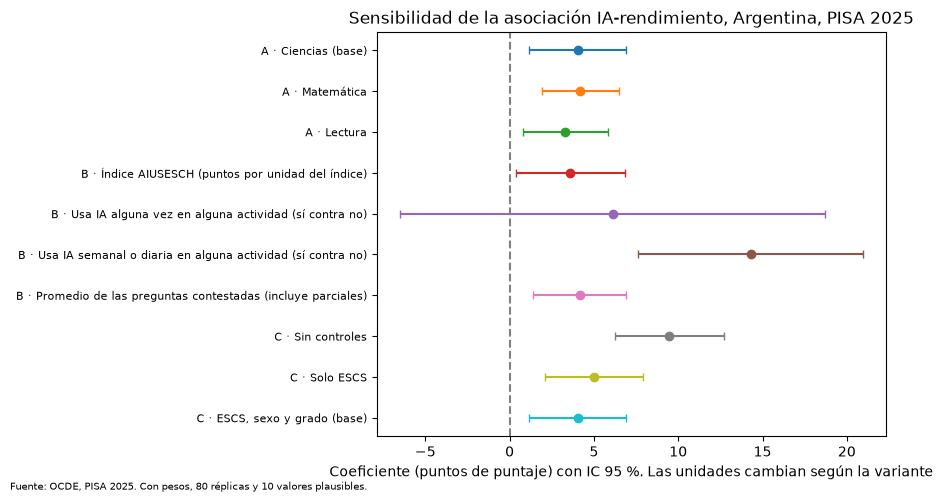

                hipotesis                                                             parametro     n  estimacion  p_texto                      veredicto
0                 A. Área                                                       Ciencias (base)  7191       4.027   0.0063  compatible con una asociación
1                 A. Área                                                            Matemática  7191       4.191   0.0003  compatible con una asociación
2                 A. Área                                                               Lectura  7191       3.314   0.0097  compatible con una asociación
3         B. Medida de IA                        Índice AIUSESCH (puntos por unidad del índice)  7431       3.607   0.0295  compatible con una asociación
4         B. Medida de IA                  Usa IA alguna vez en alguna actividad (sí contra no)  7191       6.105   0.3427         evidencia insuficiente
5         B. Medida de IA            Usa IA semanal o diaria en alguna activ

In [11]:
tabla = pd.DataFrame(resultados)
tabla.to_csv(carpeta_tablas / "04_sensibilidad.csv", index=False)

# Figura: coeficientes de las variantes del bloque A, B y C (cada uno con su unidad)
bloques = tabla[tabla["hipotesis"].isin(["A. Área", "B. Medida de IA", "C. Controles"])]

fig, eje = plt.subplots(figsize=(9, 5))
posicion = 0
nombres = []
for _, fila in bloques.iterrows():
    eje.errorbar(fila["estimacion"], posicion,
                 xerr=1.96 * fila["error_estandar"], fmt="o", capsize=3)
    nombres.append(fila["hipotesis"][0] + " · " + fila["parametro"])
    posicion = posicion + 1

eje.axvline(0, color="gray", linestyle="--")
eje.set_yticks(range(len(nombres)))
eje.set_yticklabels(nombres, fontsize=8)
eje.invert_yaxis()
eje.set_xlabel("Coeficiente (puntos de puntaje) con IC 95 %. Las unidades cambian según la variante")
eje.set_title("Sensibilidad de la asociación IA-rendimiento, Argentina, PISA 2025")
fig.text(0.01, 0.01, "Fuente: OCDE, PISA 2025. Con pesos, 80 réplicas y 10 valores plausibles.", fontsize=7)
fig.tight_layout()
fig.savefig(carpeta_figuras / "04_sensibilidad.png", dpi=120)
plt.show()

print(tabla[["hipotesis", "parametro", "n", "estimacion", "p_texto", "veredicto"]].to_string())

## 8. Evaluación y decisión

**Qué se mantiene en todas las variantes.**
- El signo de la asociación entre uso frecuente de IA y puntaje es positivo en todas las variantes.
- El patrón por actividad se repite: investigar, ayudar a aprender y resumir se asocian con más puntaje; redactar borradores no es concluyente.
- El tamaño ajustado ronda los 3 a 4 puntos por punto de frecuencia en las tres áreas y con distintas medidas de IA.

**Qué depende de las decisiones.**
- El tamaño depende mucho de los controles: baja de +9,5 a +4,0 al ajustar. Con otros controles disponibles en PISA que no usamos, podría bajar más.
- Con la definición "alguna vez" no hay resultado concluyente, porque casi todos usaron IA alguna vez.

**Qué no pudimos evaluar.**
- No se probó cómo cambiaría todo si los estudiantes que no contestaron (alrededor de un tercio, que rinden menos) hubieran contestado. Es el límite más importante.
- No se contrastó contra otro software estadístico ni se confirmó el factor de Fay en la documentación técnica.

**Decisión.** Se continúa con el informe final: las conclusiones sobre la asociación son estables en signo y patrón, pero hay que comunicar que valen para quienes contestaron, que el tamaño es modesto y que no son causales.